# **Muestra: Matriz de Co-Ocurrencia (GLCM)**

Esta es una muestra de otra forma clásica de describir texturas: la **matriz de co-ocurrencia de niveles de gris** (*Gray Level Co-occurrence Matrix*, GLCM). A diferencia de los laboratorios, acá no hay ejercicios: el código ya está completo y la idea es recorrerlo, explorar los controles interactivos y ver cómo se usa para segmentar una imagen por textura.

La idea viene del mismo problema que vimos con LBP: el histograma de una textura cuenta *cuántos* píxeles hay de cada gris, pero no dice nada sobre *dónde* están. La GLCM cuenta, en cambio, qué **pares** de niveles de gris aparecen a cierta distancia y en cierta dirección.

## **Imports**

In [1]:
# === IMPORTS ===
import time
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact, IntSlider
from collections import Counter
from itertools import permutations
from skimage import util, io
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import threshold_multiotsu
from sklearn.cluster import KMeans

## **Carga de Imágenes**

Vamos a usar ocho fotos de texturas (manchadas, rotas, fibrosas...) del dataset DTD. Esta celda las descarga (funciona en Colab y localmente). Si la carpeta ya existe no vuelve a descargar nada.

In [2]:
#@title Descargar las imagenes { display-mode: "form" }
import io as _io
import os
import urllib.request
import zipfile

REPOSITORIO_URL = "https://github.com/Elementos-Reconocimiento-Visual-UBA/PracticasERV_2026_4toBim"  #@param {type:"string"}
RAMA = "main"  #@param {type:"string"}
CARPETA_EN_REPOSITORIO = "Laboratorio_3_Texturas/imagenes"  #@param {type:"string"}
CARPETA_IMAGENES = "imagenes"  # carpeta local donde quedan las texturas

def leer_zip(url_zip):
  with urllib.request.urlopen(url_zip) as respuesta:
    return zipfile.ZipFile(_io.BytesIO(respuesta.read()))

def descargar_carpeta_de_github(url_zip, carpeta_en_repositorio, carpeta_local):
  # El zip de GitHub tiene todo dentro de una carpeta raiz: <repo>-<rama>/<carpeta_en_repositorio>/archivo
  zip_repositorio = leer_zip(url_zip)

  os.makedirs(carpeta_local, exist_ok=True)
  for nombre in zip_repositorio.namelist():
    # Sacamos la carpeta raiz y nos quedamos con los archivos que estan directamente en la carpeta pedida
    ruta = nombre.split("/", 1)[1] if "/" in nombre else ""
    carpeta, _, archivo = ruta.rpartition("/")
    if carpeta == carpeta_en_repositorio.strip("/") and archivo != "":
      with open(os.path.join(carpeta_local, archivo), "wb") as salida:
        salida.write(zip_repositorio.read(nombre))

if os.path.isdir(CARPETA_IMAGENES):
  print(f"La carpeta {CARPETA_IMAGENES} ya existe, no se descarga nada")
else:
  descargar_carpeta_de_github(f"{REPOSITORIO_URL.rstrip('/')}/archive/refs/heads/{RAMA}.zip", CARPETA_EN_REPOSITORIO, CARPETA_IMAGENES)
  print(f"Descargadas {len(os.listdir(CARPETA_IMAGENES))} imagenes en {CARPETA_IMAGENES}")

La carpeta imagenes ya existe, no se descarga nada


## **TEXTURAS**

In [3]:
TEXTURAS = {
  'manchado 1': 'blotchy_0009.jpg',  'manchado 2': 'blotchy_0017.jpg',
  'roto 1':     'cracked_0004.jpg',  'roto 2':     'cracked_0046.jpg',
  'fibroso 1':  'fibrous_0083.jpg',  'fibroso 2':  'fibrous_0095.jpg',
  'moteado':    'flecked_0050.jpg',  'cristalino': 'crystalline_0057.jpg',
}
LADO_TEXTURA = 192

def cargar_textura(nombre, lado=LADO_TEXTURA):
  # Nos quedamos con un recorte cuadrado del centro de la foto
  imagen = util.img_as_ubyte(io.imread(f"{CARPETA_IMAGENES}/{TEXTURAS[nombre]}", as_gray=True))
  fila_inicio = (imagen.shape[0] - lado) // 2
  columna_inicio = (imagen.shape[1] - lado) // 2
  return imagen[fila_inicio:fila_inicio + lado, columna_inicio:columna_inicio + lado]

## **Matriz de Co-Ocurrencia (GLCM)**

### **Idea**

LBP se queda con un único dato por cada vecino: si es mayor o menor que el central. Tira a la basura **cuánto** mayor o menor, y solo mira una vecindad chiquita alrededor de cada píxel. La **matriz de co-ocurrencia de niveles de gris** (**GLCM**) guarda más información: dado un **desplazamiento** (por ejemplo, "un píxel hacia la derecha"), cuenta **cuántas veces aparece cada par** de niveles de gris a esa distancia.

Es un histograma, pero de **pares** de píxeles en vez de píxeles sueltos. Como una textura es un patrón que se repite, la GLCM captura *cada cuánto* se repite y *con qué contraste*: por eso se la suele llamar la **huella digital** de la textura.

Sea $I(y, x)$ una imagen con $L$ niveles de gris $\{0, \dots, L-1\}$. Su GLCM con desplazamiento $(\Delta y, \Delta x)$ es una matriz de $L \times L$ donde el casillero $(i, j)$ cuenta los píxeles de valor $i$ cuyo vecino desplazado vale $j$:

$$C_{(\Delta y, \Delta x)}[i, j] = \sum_{y, x} \begin{cases} 1 & \text{si } I(y, x) = i \text{ y } I(y + \Delta y, x + \Delta x) = j \\ 0 & \text{si no} \end{cases}$$

Los pares cuyo destino cae fuera de la imagen simplemente no se cuentan.

Hay varias formas de elegir el desplazamiento. Una muy usada es con una **distancia** $d$ y un **ángulo** $\theta$:

$$\Delta y = \text{round}\left(d \cdot \sin\theta\right) \qquad \Delta x = \text{round}\left(d \cdot \cos\theta\right)$$

Como las filas crecen hacia abajo, $\theta = 0°$ es hacia la derecha y $\theta = 90°$ es hacia **abajo**.

Hay tres detalles prácticos:

- **Cuantización**: con $256$ niveles la matriz tiene $65536$ casilleros y casi todos quedan vacíos (el mismo problema que vimos con los $2^P$ códigos de LBP). Antes de contar se reducen los grises a $8$, $16$ o $32$ niveles.
- **Simétrica**: si no nos importa el *sentido* del desplazamiento (derecha o izquierda) sumamos la matriz con su traspuesta, así el par $(i, j)$ cuenta igual que el $(j, i)$.
- **Normalizada**: si dividimos por la cantidad total de pares, cada casillero pasa a ser la **probabilidad** de ver ese par, $P(i, j)$, y la suma da $1$. Así podemos comparar imágenes de distinto tamaño.

Veamos cómo se construye. Esta es una imagen de $8 \times 8$ con $4$ niveles de gris. Con el slider **paso** van recorriendo los píxeles de a uno: el punto rojo es el píxel de origen $i$, el azul su vecino desplazado $j$, y en cada paso se suma $1$ al casillero $(i, j)$ de la matriz. Prueben distintos desplazamientos.

In [4]:
IMAGEN_8X8_4_NIVELES = np.array([
  [3, 3, 2, 3, 3, 3, 3, 3],
  [3, 2, 2, 3, 0, 0, 3, 3],
  [2, 2, 2, 1, 1, 0, 1, 3],
  [2, 2, 1, 1, 0, 2, 0, 1],
  [2, 1, 1, 1, 0, 0, 0, 1],
  [2, 1, 1, 0, 0, 0, 1, 3],
  [3, 3, 1, 3, 3, 0, 0, 3],
  [3, 3, 3, 3, 3, 3, 3, 3],
])

def dibujar_matriz(ax, matriz, titulo, formato="{:.0f}"):
  # Dibuja una matriz con el valor escrito en cada casillero
  ax.imshow(matriz, cmap="Blues", vmin=0, vmax=max(matriz.max(), 1))
  for fila in range(matriz.shape[0]):
    for columna in range(matriz.shape[1]):
      ax.text(columna, fila, formato.format(matriz[fila, columna]), ha="center", va="center", color="white" if matriz[fila, columna] > matriz.max() / 2 else "black")
  ax.set_xticks(range(matriz.shape[1]))
  ax.set_yticks(range(matriz.shape[0]))
  ax.set_xlabel("j: nivel del vecino")
  ax.set_ylabel("i: nivel del pixel")
  ax.set_title(titulo)

def pares_con_destino_dentro(imagen, desplazamiento_fila, desplazamiento_columna):
  # (fila, columna, fila_destino, columna_destino) de cada pixel cuyo vecino desplazado cae dentro de la imagen, recorridos por filas
  alto, ancho = imagen.shape
  return [(fila, columna, fila + desplazamiento_fila, columna + desplazamiento_columna)
          for fila in range(alto) for columna in range(ancho)
          if 0 <= fila + desplazamiento_fila < alto and 0 <= columna + desplazamiento_columna < ancho]

def explorar_construccion_glcm(desplazamiento_fila, desplazamiento_columna, paso):
  pares = pares_con_destino_dentro(IMAGEN_8X8_4_NIVELES, desplazamiento_fila, desplazamiento_columna)
  pares_contados = min(paso, len(pares))
  ultimo_par = pares[pares_contados - 1] if pares_contados > 0 else None

  # Cuantas veces aparece cada par (nivel del pixel, nivel del vecino) entre los pares contados
  repeticiones = Counter((IMAGEN_8X8_4_NIVELES[fila, columna], IMAGEN_8X8_4_NIVELES[fila_destino, columna_destino]) for fila, columna, fila_destino, columna_destino in pares[:pares_contados])
  matriz = np.array([[repeticiones[(i, j)] for j in range(4)] for i in range(4)])

  fig, ax = plt.subplots(1, 2, figsize=(11, 5))

  ax[0].imshow(IMAGEN_8X8_4_NIVELES, cmap="gray", vmin=0, vmax=3)
  for fila in range(8):
    for columna in range(8):
      ax[0].text(columna, fila, IMAGEN_8X8_4_NIVELES[fila, columna], ha="center", va="center", color="black" if IMAGEN_8X8_4_NIVELES[fila, columna] > 1 else "white", fontsize=13)
  if ultimo_par is not None:
    fila, columna, fila_destino, columna_destino = ultimo_par
    ax[0].scatter(columna, fila, color="red", s=500, alpha=0.6)
    ax[0].scatter(columna_destino, fila_destino, color="blue", s=500, alpha=0.6)
    ax[0].annotate("", xy=(columna_destino, fila_destino), xytext=(columna, fila), arrowprops=dict(arrowstyle="->", color="yellow", linewidth=2))
  ax[0].set_xticks(np.arange(-0.5, 8, 1), minor=True)
  ax[0].set_yticks(np.arange(-0.5, 8, 1), minor=True)
  ax[0].grid(True, which="minor", color="blue", linewidth=0.8)
  ax[0].tick_params(which="both", length=0, labelleft=False, labelbottom=False)
  ax[0].set_title(f"Desplazamiento ({desplazamiento_fila}, {desplazamiento_columna}): {pares_contados} pares contados")

  dibujar_matriz(ax[1], matriz, "GLCM acumulada")
  plt.tight_layout()
  plt.show()

interact(
  explorar_construccion_glcm,
  desplazamiento_fila=IntSlider(min=-3, max=3, step=1, value=1, description='delta fila'),
  desplazamiento_columna=IntSlider(min=-3, max=3, step=1, value=1, description='delta columna'),
  paso=IntSlider(min=0, max=64, step=1, value=9, description='paso'),
);

interactive(children=(IntSlider(value=1, description='delta fila', max=3, min=-3), IntSlider(value=1, descript…

### **Implementación de la GLCM**

Estas son las funciones que arman la GLCM de una imagen:

- `cuantizar` pasa de $256$ grises a `niveles` grises repartiendo el rango en partes iguales: el gris $g$ queda en el nivel $\lfloor g \cdot niveles / 256 \rfloor$. Hay que convertir a `int` antes de multiplicar, porque la imagen es `uint8` y multiplicar por `niveles` se pasa de $255$.
- `desplazamiento_polar` devuelve el par $(\Delta y, \Delta x)$ redondeado a enteros.
- `glcm` recibe una imagen que **ya está cuantizada** (sus valores van de $0$ a `niveles - 1`) y devuelve la matriz con `matriz[i, j]` = cantidad de píxeles de valor $i$ cuyo vecino desplazado vale $j$. Si `simetrica` es `True` suma la traspuesta y si `normalizada` es `True` divide por la suma total.

In [5]:
def cuantizar(imagen, niveles):
  # Pasa de 256 niveles de gris a `niveles`, repartiendo el rango en partes iguales
  return (imagen.astype(int) * niveles // 256).astype(np.uint8)

In [6]:
def desplazamiento_polar(distancia, angulo_grados):
  # (desplazamiento de fila, desplazamiento de columna) a esa distancia y ese angulo. 0 grados es hacia la derecha y 90 hacia abajo
  angulo = np.radians(angulo_grados)
  return int(np.round(distancia * np.sin(angulo))), int(np.round(distancia * np.cos(angulo)))

In [7]:
def glcm(imagen, desplazamiento, niveles, simetrica=False, normalizada=False):
  # matriz[i, j] = cantidad de pixeles de valor i cuyo vecino desplazado vale j
  alto, ancho = imagen.shape
  desplazamiento_fila, desplazamiento_columna = desplazamiento
  matriz = np.zeros((niveles, niveles))

  for fila in range(alto):
    for columna in range(ancho):
      fila_destino = fila + desplazamiento_fila
      columna_destino = columna + desplazamiento_columna
      if not (0 <= fila_destino < alto and 0 <= columna_destino < ancho): continue

      matriz[imagen[fila, columna], imagen[fila_destino, columna_destino]] += 1

  if simetrica: matriz = matriz + matriz.T
  if normalizada and matriz.sum() > 0: matriz = matriz / matriz.sum()

  return matriz

### Tests (GLCM)

In [8]:
# nombre: (imagen de 256 grises, cantidad de niveles, imagen cuantizada esperada)
CUANTIZACIONES_ESPERADAS = {
  'cuatro_niveles': (np.array([[0, 63, 64, 127], [128, 191, 192, 255]], dtype=np.uint8), 4, np.array([[0, 0, 1, 1], [2, 2, 3, 3]])),
  'dos_niveles':    (np.array([[0, 127, 128, 255]], dtype=np.uint8),                    2, np.array([[0, 0, 1, 1]])),
  'sin_cambios':    (np.array([[0, 100, 255]], dtype=np.uint8),                         256, np.array([[0, 100, 255]])),
}

# nombre: (distancia, angulo en grados, desplazamiento esperado (fila, columna))
DESPLAZAMIENTOS_ESPERADOS = {
  'derecha':          (1, 0,   (0, 1)),
  'abajo':            (1, 90,  (1, 0)),
  'diagonal':         (1, 45,  (1, 1)),
  'diagonal_inversa': (1, 135, (1, -1)),
  'izquierda':        (2, 180, (0, -2)),
  'distancia_3':      (3, 0,   (0, 3)),
  'diagonal_lejana':  (3, 45,  (2, 2)),  # 3 * sin(45) = 2.12 se redondea a 2
}

IMAGEN_GLCM_CHICA = np.array([[3, 3, 2, 3], [3, 2, 2, 3], [2, 0, 0, 1], [2, 2, 0, 0]])
IMAGEN_GLCM_HORIZONTAL = np.array([[0, 1, 1], [2, 2, 0]])

# nombre: (imagen, desplazamiento, niveles, simetrica, normalizada, matriz esperada)
GLCMS_ESPERADAS = {
  'ejemplo_4x4':   (IMAGEN_GLCM_CHICA, (1, 1), 4, False, False, np.array([[2, 0, 0, 0], [0, 0, 0, 0], [1, 1, 1, 1], [1, 0, 2, 0]])),
  'horizontal':    (IMAGEN_GLCM_HORIZONTAL, (0, 1), 3, False, False, np.array([[0, 1, 0], [0, 1, 0], [1, 0, 1]])),
  'simetrica':     (IMAGEN_GLCM_HORIZONTAL, (0, 1), 3, True, False, np.array([[0, 1, 1], [1, 2, 0], [1, 0, 2]])),
  'normalizada':   (IMAGEN_GLCM_HORIZONTAL, (0, 1), 3, False, True, np.array([[0, 1, 0], [0, 1, 0], [1, 0, 1]]) / 4),
  'sin_pares':     (IMAGEN_GLCM_CHICA, (5, 5), 4, False, False, np.zeros((4, 4))),
  'izquierda':     (IMAGEN_GLCM_HORIZONTAL, (0, -1), 3, False, False, np.array([[0, 0, 1], [1, 1, 0], [0, 0, 1]])),  # es la traspuesta de 'horizontal'
}

def verificar_cuantizar(nombre):
  imagen, niveles, esperada = CUANTIZACIONES_ESPERADAS[nombre]
  obtenida = cuantizar(imagen, niveles)

  assert np.array_equal(obtenida, esperada), f"[{nombre}] se esperaba {esperada.tolist()} pero se obtuvo {np.asarray(obtenida).tolist()}"
  print(f"OK [{nombre}] {niveles} niveles: {np.asarray(obtenida).tolist()}")

def verificar_desplazamiento(nombre):
  distancia, angulo, esperado = DESPLAZAMIENTOS_ESPERADOS[nombre]
  obtenido = tuple(int(valor) for valor in desplazamiento_polar(distancia, angulo))

  assert obtenido == esperado, f"[{nombre}] se esperaba {esperado} pero se obtuvo {obtenido}"
  print(f"OK [{nombre}] distancia {distancia}, angulo {angulo}: {obtenido}")

def verificar_glcm(nombre):
  imagen, desplazamiento, niveles, simetrica, normalizada, esperada = GLCMS_ESPERADAS[nombre]
  obtenida = glcm(imagen, desplazamiento, niveles, simetrica, normalizada)

  assert obtenida.shape == esperada.shape, f"[{nombre}] se esperaba una matriz de forma {esperada.shape} pero se obtuvo {obtenida.shape}"
  assert np.allclose(obtenida, esperada), f"[{nombre}] se esperaba {esperada.tolist()} pero se obtuvo {obtenida.tolist()}"
  total = "suma 1" if normalizada else f"{int(obtenida.sum())} en total"
  print(f"OK [{nombre}] {total}")

def verificar_glcm_contra_skimage(distancia, angulo_grados, simetrica, normalizada):
  # skimage usa la misma convencion: el angulo 0 es la derecha y el 90 es hacia abajo
  imagen = cuantizar(cargar_textura('roto 1', 40), 16)
  esperada = graycomatrix(imagen, [distancia], [np.radians(angulo_grados)], levels=16, symmetric=simetrica, normed=normalizada)[:, :, 0, 0]
  obtenida = glcm(imagen, desplazamiento_polar(distancia, angulo_grados), 16, simetrica, normalizada)

  assert np.allclose(obtenida, esperada), f"[d={distancia}, angulo={angulo_grados}] la GLCM no coincide con skimage en {(~np.isclose(obtenida, esperada)).sum()} casilleros"
  print(f"OK [d={distancia}, angulo={angulo_grados}, simetrica={simetrica}, normalizada={normalizada}] coincide con skimage")

### Verificacion cuantizar

In [9]:
for nombre in CUANTIZACIONES_ESPERADAS:
  verificar_cuantizar(nombre)

OK [cuatro_niveles] 4 niveles: [[0, 0, 1, 1], [2, 2, 3, 3]]
OK [dos_niveles] 2 niveles: [[0, 0, 1, 1]]
OK [sin_cambios] 256 niveles: [[0, 100, 255]]


### Verificacion desplazamiento

In [10]:
for nombre in DESPLAZAMIENTOS_ESPERADOS:
  verificar_desplazamiento(nombre)

OK [derecha] distancia 1, angulo 0: (0, 1)
OK [abajo] distancia 1, angulo 90: (1, 0)
OK [diagonal] distancia 1, angulo 45: (1, 1)
OK [diagonal_inversa] distancia 1, angulo 135: (1, -1)
OK [izquierda] distancia 2, angulo 180: (0, -2)
OK [distancia_3] distancia 3, angulo 0: (0, 3)
OK [diagonal_lejana] distancia 3, angulo 45: (2, 2)


### Verificacion GLCM

In [11]:
for nombre in GLCMS_ESPERADAS:
  verificar_glcm(nombre)

for distancia, angulo_grados in [(1, 0), (2, 45), (3, 90), (2, 135)]:
  verificar_glcm_contra_skimage(distancia, angulo_grados, True, True)
verificar_glcm_contra_skimage(1, 0, False, False)

OK [ejemplo_4x4] 9 en total
OK [horizontal] 4 en total
OK [simetrica] 8 en total
OK [normalizada] suma 1
OK [sin_pares] 0 en total
OK [izquierda] 4 en total
OK [d=1, angulo=0, simetrica=True, normalizada=True] coincide con skimage
OK [d=2, angulo=45, simetrica=True, normalizada=True] coincide con skimage
OK [d=3, angulo=90, simetrica=True, normalizada=True] coincide con skimage
OK [d=2, angulo=135, simetrica=True, normalizada=True] coincide con skimage
OK [d=1, angulo=0, simetrica=False, normalizada=False] coincide con skimage


#### Versión vectorizada

La versión con loops es lenta. Pero acá no hace falta ni siquiera calcular coordenadas: si **recortamos** la imagen para quedarnos con los píxeles de origen que tienen destino y recortamos **la misma cantidad desplazada** para los destinos, obtenemos dos arreglos del mismo tamaño que son, casilla por casilla, los pares $(i, j)$. Solo falta contarlos, y como hay pares repetidos usamos `np.add.at`, igual que en Hough.

Para un desplazamiento $(\Delta y, \Delta x)$ los píxeles de origen son los de las filas `max(0, -dy)` a `alto - max(0, dy)` y las columnas `max(0, -dx)` a `ancho - max(0, dx)`. Los destinos son el mismo recorte pero corrido: filas desde `max(0, dy)` hasta `alto - max(0, -dy)` y columnas desde `max(0, dx)` hasta `ancho - max(0, -dx)`. Si el desplazamiento es mayor que la imagen no hay ningún par y la matriz queda en ceros.

In [12]:
def glcm_vectorizada(imagen, desplazamiento, niveles, simetrica=False, normalizada=False):
  alto, ancho = imagen.shape
  desplazamiento_fila, desplazamiento_columna = desplazamiento
  matriz = np.zeros((niveles, niveles))

  if abs(desplazamiento_fila) < alto and abs(desplazamiento_columna) < ancho:
    origenes = imagen[max(0, -desplazamiento_fila):alto - max(0, desplazamiento_fila), max(0, -desplazamiento_columna):ancho - max(0, desplazamiento_columna)]
    destinos = imagen[max(0, desplazamiento_fila):alto - max(0, -desplazamiento_fila), max(0, desplazamiento_columna):ancho - max(0, -desplazamiento_columna)]
    np.add.at(matriz, (origenes.ravel(), destinos.ravel()), 1)

  if simetrica: matriz = matriz + matriz.T
  if normalizada and matriz.sum() > 0: matriz = matriz / matriz.sum()

  return matriz

### Verificacion Vectorizado (GLCM)

In [13]:
def verificar_glcm_vectorizada(desplazamiento):
  imagen = cuantizar(cargar_textura('fibroso 2', 64), 16)

  inicio = time.perf_counter()
  esperada = glcm(imagen, desplazamiento, 16, True, True)
  tiempo_loop = time.perf_counter() - inicio

  inicio = time.perf_counter()
  obtenida = glcm_vectorizada(imagen, desplazamiento, 16, True, True)
  tiempo_vectorizada = time.perf_counter() - inicio

  assert np.allclose(obtenida, esperada), f"[{desplazamiento}] la GLCM vectorizada no coincide con la de los loops en {(~np.isclose(obtenida, esperada)).sum()} casilleros"
  print(f"OK [{desplazamiento}] loop: {tiempo_loop * 1000:.1f} ms, vectorizada: {tiempo_vectorizada * 1000:.1f} ms")

for desplazamiento in [(0, 1), (1, 1), (3, 0), (-2, 2), (80, 80)]:
  verificar_glcm_vectorizada(desplazamiento)

OK [(0, 1)] loop: 4.5 ms, vectorizada: 0.6 ms
OK [(1, 1)] loop: 4.0 ms, vectorizada: 0.7 ms
OK [(3, 0)] loop: 4.3 ms, vectorizada: 0.9 ms
OK [(-2, 2)] loop: 5.3 ms, vectorizada: 0.6 ms
OK [(80, 80)] loop: 0.5 ms, vectorizada: 0.0 ms


### **Descriptores de Haralick**

Una GLCM de $16 \times 16$ ya son $256$ números, y además cambia con cada desplazamiento. Para usarla como descriptor se resume en unos pocos números llamados **descriptores de Haralick** (Haralick et al., 1973), que miden cosas con significado: qué tan **contrastada**, **homogénea**, **ordenada** o **predecible** es la textura. Sea $P(i, j)$ la GLCM normalizada:

$$\text{Contraste} = \sum_{i,j} (i - j)^2 \, P(i,j) \qquad \text{Disimilitud} = \sum_{i,j} |i - j| \, P(i,j)$$

$$\text{Homogeneidad} = \sum_{i,j} \frac{P(i,j)}{1 + (i - j)^2} \qquad \text{Energía} = \sqrt{\sum_{i,j} P(i,j)^2}$$

$$\text{Correlación} = \sum_{i,j} \frac{(i - \mu_i)(j - \mu_j)}{\sigma_i \sigma_j} \, P(i,j)$$

donde $\mu_i = \sum_{i,j} i \cdot P(i,j)$ y $\sigma_i^2 = \sum_{i,j} (i - \mu_i)^2 P(i,j)$, y lo mismo con $j$. ¿Qué miden?

- El **contraste** y la disimilitud son altos cuando son frecuentes los pares de grises muy distintos (casilleros lejos de la diagonal). La **homogeneidad** es lo opuesto: es alta cuando los pares son parecidos (casilleros sobre la diagonal).
- La **energía** es alta cuando pocos pares concentran casi toda la probabilidad: una textura regular, repetitiva, ordenada.
- La **correlación** mide qué tan bien se puede predecir el gris de un píxel a partir del gris de su vecino.

### **Implementación de Haralick**

Están dadas `grillas_de_niveles`, que devuelve las matrices $i$ y $j$ con el nivel de cada casillero, y las propiedades `disimilitud`, `contraste`, `homogeneidad`, `energia` y `correlacion`. En la correlación, si algún $\sigma$ es $0$ (la imagen es plana) se devuelve $1$, que es lo que hace skimage.

In [14]:
def grillas_de_niveles(glcm_normalizada):
  # i[f, c] = f (nivel del pixel) y j[f, c] = c (nivel del vecino) para cada casillero
  return np.indices(glcm_normalizada.shape)

def disimilitud(glcm_normalizada):
  i, j = grillas_de_niveles(glcm_normalizada)
  return np.sum(np.abs(i - j) * glcm_normalizada)

In [15]:
def contraste(glcm_normalizada):
  i, j = grillas_de_niveles(glcm_normalizada)
  return np.sum((i - j) ** 2 * glcm_normalizada)

def homogeneidad(glcm_normalizada):
  i, j = grillas_de_niveles(glcm_normalizada)
  return np.sum(glcm_normalizada / (1 + (i - j) ** 2))

def energia(glcm_normalizada):
  return np.sqrt(np.sum(glcm_normalizada ** 2))

def correlacion(glcm_normalizada):
  i, j = grillas_de_niveles(glcm_normalizada)
  media_i = np.sum(i * glcm_normalizada)
  media_j = np.sum(j * glcm_normalizada)
  desvio_i = np.sqrt(np.sum((i - media_i) ** 2 * glcm_normalizada))
  desvio_j = np.sqrt(np.sum((j - media_j) ** 2 * glcm_normalizada))
  if desvio_i * desvio_j == 0: return 1.0

  return np.sum((i - media_i) * (j - media_j) * glcm_normalizada) / (desvio_i * desvio_j)

def propiedades_de_glcm(glcm_normalizada):
  # Las cuatro propiedades, en este orden: contraste, homogeneidad, energia, correlacion
  return [contraste(glcm_normalizada), homogeneidad(glcm_normalizada), energia(glcm_normalizada), correlacion(glcm_normalizada)]

### Tests (Haralick)

In [16]:
# nombre: (GLCM normalizada de 4x4, [contraste, homogeneidad, energia, correlacion] esperados)
GLCM_UN_SOLO_PAR = np.zeros((4, 4))
GLCM_UN_SOLO_PAR[0, 3] = 1
PROPIEDADES_ESPERADAS = {
  'diagonal_uniforme': (np.eye(4) / 4,             [0, 1, 0.5, 1]),      # solo hay pares de grises iguales
  'uniforme_total':    (np.full((4, 4), 1 / 16),   [2.5, 0.5, 0.25, 0]),  # todos los pares son igual de probables
  'un_solo_par':       (GLCM_UN_SOLO_PAR,          [9, 0.1, 1, 1]),       # el unico par es (0, 3) y la correlacion de algo constante vale 1
}

NOMBRES_PROPIEDADES_SKIMAGE = {'contraste': 'contrast', 'homogeneidad': 'homogeneity', 'energia': 'energy', 'correlacion': 'correlation'}

def verificar_propiedades(nombre):
  matriz, esperadas = PROPIEDADES_ESPERADAS[nombre]
  obtenidas = propiedades_de_glcm(matriz)

  assert np.allclose(obtenidas, esperadas), f"[{nombre}] se esperaban {esperadas} pero se obtuvo {np.round(obtenidas, 4).tolist()}"
  print(f"OK [{nombre}] {np.round(obtenidas, 4).tolist()}")

def verificar_propiedades_contra_skimage(nombre_textura):
  imagen = cuantizar(cargar_textura(nombre_textura, 64), 16)
  matriz_skimage = graycomatrix(imagen, [2], [0], levels=16, symmetric=True, normed=True)
  esperadas = [graycoprops(matriz_skimage, nombre)[0, 0] for nombre in NOMBRES_PROPIEDADES_SKIMAGE.values()]
  obtenidas = propiedades_de_glcm(matriz_skimage[:, :, 0, 0])

  assert np.allclose(obtenidas, esperadas), f"[{nombre_textura}] skimage da {np.round(esperadas, 4).tolist()} pero se obtuvo {np.round(obtenidas, 4).tolist()}"
  print(f"OK [{nombre_textura}] {np.round(obtenidas, 4).tolist()} (skimage: {np.round(esperadas, 4).tolist()})")

### Verificacion Haralick

In [17]:
for nombre in PROPIEDADES_ESPERADAS:
  verificar_propiedades(nombre)

for nombre_textura in ['roto 1', 'fibroso 2', 'moteado']:
  verificar_propiedades_contra_skimage(nombre_textura)

OK [diagonal_uniforme] [0.0, 1.0, 0.5, 1.0]
OK [uniforme_total] [2.5, 0.5, 0.25, 0.0]
OK [un_solo_par] [9.0, 0.1, 1.0, 1.0]
OK [roto 1] [9.621, 0.4379, 0.1302, 0.6579] (skimage: [9.621, 0.4379, 0.1302, 0.6579])
OK [fibroso 2] [4.6799, 0.4513, 0.1611, 0.3467] (skimage: [4.6799, 0.4513, 0.1611, 0.3467])
OK [moteado] [8.5076, 0.504, 0.3638, 0.2163] (skimage: [8.5076, 0.504, 0.3638, 0.2163])


#### **Ejemplos**

Ahora a explorar. Elijan una textura, una distancia y un ángulo, y miren cómo cambian la GLCM (de $16$ niveles, simétrica y normalizada, calculada con **nuestra** función) y sus propiedades. En una textura con detalles chicos como `moteado` la GLCM se aleja de la diagonal muy rápido al aumentar la distancia, mientras que en una textura con manchas grandes se queda cerca de la diagonal.

In [18]:
NOMBRES_PROPIEDADES = ['contraste', 'homogeneidad', 'energia', 'correlacion']

def explorar_glcm_de_textura(textura, distancia, angulo):
  recorte = cargar_textura(textura, 64)
  matriz = glcm(cuantizar(recorte, 16), desplazamiento_polar(distancia, angulo), 16, simetrica=True, normalizada=True)
  propiedades = propiedades_de_glcm(matriz)

  fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

  ax[0].imshow(recorte, cmap="gray", vmin=0, vmax=255)
  ax[0].set_title(f"{textura} (recorte de 64x64)")
  ax[0].axis("off")

  ax[1].imshow(np.sqrt(matriz), cmap="Blues")  # la raiz hace que se vean tambien los casilleros chicos
  ax[1].set_xlabel("j")
  ax[1].set_ylabel("i")
  ax[1].set_title(f"GLCM (d={distancia}, angulo={angulo}) en raiz")

  ax[2].axis("off")
  for posicion, (nombre, valor) in enumerate(zip(NOMBRES_PROPIEDADES, propiedades)):
    ax[2].text(0.05, 0.85 - 0.2 * posicion, f"{nombre}: {valor:.3f}", fontsize=16, transform=ax[2].transAxes)
  ax[2].set_title("Propiedades")

  plt.tight_layout()
  plt.show()

interact(
  explorar_glcm_de_textura,
  textura=widgets.Dropdown(options=list(TEXTURAS), value='moteado', description='textura'),
  distancia=IntSlider(min=1, max=10, step=1, value=1, description='distancia'),
  angulo=widgets.SelectionSlider(options=[0, 45, 90, 135], value=0, description='angulo'),
);

interactive(children=(Dropdown(description='textura', index=6, options=('manchado 1', 'manchado 2', 'roto 1', …

La GLCM además es muy buena para detectar **periodicidades**. Si la textura son rayas con un período de $T$ píxeles, un píxel y otro a distancia $T$ (en la dirección de la variación) valen casi lo mismo: la GLCM se pega a la diagonal y el contraste se hace casi cero. A distancia $T/2$, en cambio, un píxel es una cresta y el otro un valle: el contraste es máximo. Veamos el contraste en función de la distancia para rayas sintéticas.

In [19]:
def crear_rayas(periodo, lado=64):
  # Rayas verticales que varian con un seno de periodo `periodo`
  columnas = np.arange(lado)
  fila = np.round(127.5 + 127.5 * np.sin(2 * np.pi * columnas / periodo)).astype(np.uint8)
  return np.tile(fila, (lado, 1))

def explorar_rayas(periodo, distancia):
  rayas = cuantizar(crear_rayas(periodo), 16)
  distancias = list(range(1, 21))
  contrastes = [contraste(glcm(rayas, desplazamiento_polar(d, 0), 16, simetrica=True, normalizada=True)) for d in distancias]
  matriz = glcm(rayas, desplazamiento_polar(distancia, 0), 16, simetrica=True, normalizada=True)

  fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

  ax[0].imshow(rayas, cmap="gray", vmin=0, vmax=15)
  ax[0].set_title(f"Rayas de periodo {periodo}")
  ax[0].axis("off")

  ax[1].imshow(np.sqrt(matriz), cmap="Blues")
  ax[1].set_xlabel("j")
  ax[1].set_ylabel("i")
  ax[1].set_title(f"GLCM con d={distancia}, angulo=0")

  ax[2].plot(distancias, contrastes, marker="o")
  ax[2].plot([distancia], [contrastes[distancia - 1]], marker="o", markersize=12, color="red")
  ax[2].set_xlabel("distancia")
  ax[2].set_ylabel("contraste")
  ax[2].set_xticks(distancias[::2])
  ax[2].set_title("Contraste segun la distancia")
  ax[2].grid(True)

  plt.tight_layout()
  plt.show()

interact(
  explorar_rayas,
  periodo=IntSlider(min=4, max=16, step=1, value=8, description='periodo'),
  distancia=IntSlider(min=1, max=20, step=1, value=4, description='distancia'),
);

interactive(children=(IntSlider(value=8, description='periodo', max=16, min=4), IntSlider(value=4, description…

### **Segmentación por textura**

Ya tenemos todo para hacer una segmentación como las del laboratorio anterior, pero en lugar de mirar la intensidad de **cada píxel** vamos a mirar la **textura de cada parche**. La receta es:

1. Dividir la imagen en **parches** cuadrados.
2. Calcular un **vector de características** por parche: las propiedades de Haralick de su GLCM, para algunos ángulos.
3. **Agrupar** (clustering) los vectores: los parches con texturas parecidas caen en el mismo grupo.
4. Pintar cada parche con el color de su grupo.

Armemos una imagen de prueba: un **mosaico** con tres texturas distintas, arriba a la izquierda, arriba a la derecha y abajo. Para que sea un desafío justo **igualamos la media y el desvío** de las tres, así no se distinguen por su brillo. Probemos primero lo que ya sabemos, el **Otsu multinivel** del laboratorio anterior.

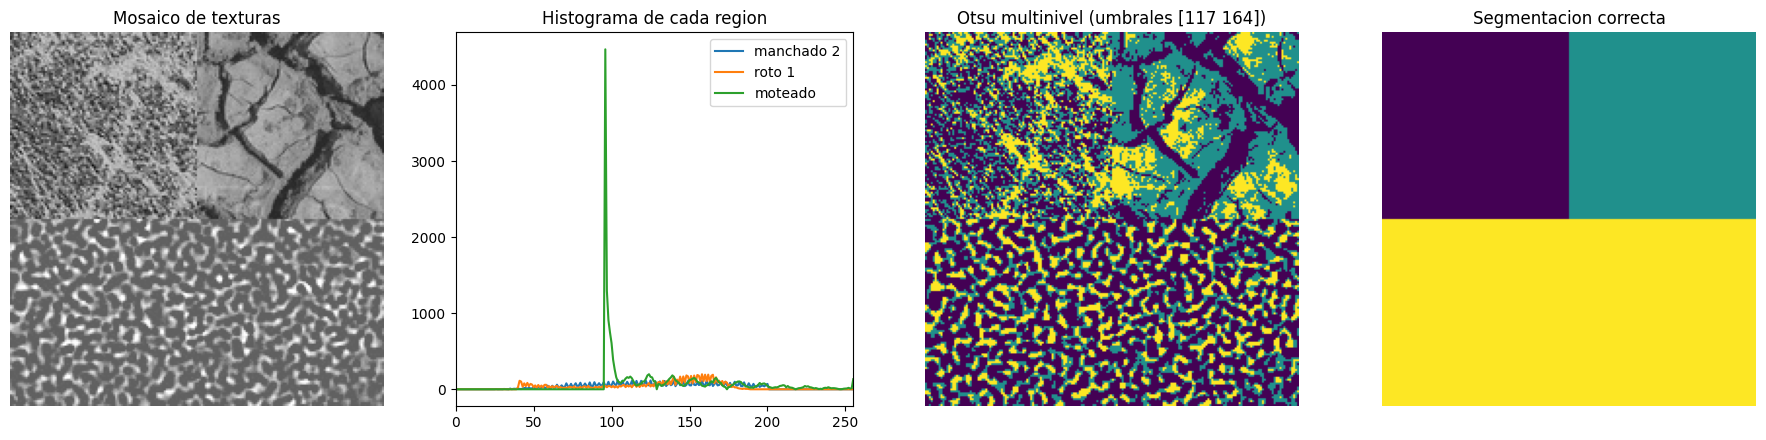

In [20]:
def igualar_media_y_desvio(imagen, media=128, desvio=40):
  imagen_normalizada = (imagen.astype(float) - imagen.mean()) / imagen.std() * desvio + media
  return np.clip(imagen_normalizada, 0, 255).astype(np.uint8)

def crear_mosaico(nombres_texturas, lado=192):
  # Arriba a la izquierda la textura 1, arriba a la derecha la 2 y abajo la 3. Devuelve la imagen y la etiqueta (0, 1 o 2) de cada pixel
  texturas = [igualar_media_y_desvio(cargar_textura(nombre, lado)) for nombre in nombres_texturas]
  mitad = lado // 2
  mosaico = np.zeros((lado, lado), dtype=np.uint8)
  etiquetas = np.zeros((lado, lado), dtype=int)

  mosaico[:mitad, :mitad] = texturas[0][:mitad, :mitad]
  mosaico[:mitad, mitad:] = texturas[1][:mitad, mitad:]
  mosaico[mitad:, :] = texturas[2][mitad:, :]
  etiquetas[:mitad, mitad:] = 1
  etiquetas[mitad:, :] = 2
  return mosaico, etiquetas

TEXTURAS_DEL_MOSAICO = ['manchado 2', 'roto 1', 'moteado']
mosaico, etiquetas_reales = crear_mosaico(TEXTURAS_DEL_MOSAICO)

umbrales = threshold_multiotsu(mosaico, classes=3)
segmentacion_otsu = np.digitize(mosaico, umbrales)

fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))

ax[0].imshow(mosaico, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Mosaico de texturas")
ax[0].axis("off")

for etiqueta, nombre in enumerate(TEXTURAS_DEL_MOSAICO):
  ax[1].plot(np.bincount(mosaico[etiquetas_reales == etiqueta], minlength=256), label=nombre)
ax[1].set_title("Histograma de cada region")
ax[1].set_xlim(0, 255)
ax[1].legend()

ax[2].imshow(segmentacion_otsu, cmap="viridis")
ax[2].set_title(f"Otsu multinivel (umbrales {umbrales})")
ax[2].axis("off")

ax[3].imshow(etiquetas_reales, cmap="viridis")
ax[3].set_title("Segmentacion correcta")
ax[3].axis("off")

plt.tight_layout()
plt.show()

Como era de esperar, **Otsu no puede**: las tres regiones tienen la misma media y el mismo desvío, sus histogramas se superponen y ningún umbral las separa (fijense cómo el resultado mezcla las tres). Es lo mismo que vimos en el cuaderno de LBP con el histograma de las texturas mezcladas. Lo que las diferencia es la **organización** de los grises y eso es justamente lo que mide la GLCM.

### **Implementación**

Estas son las funciones que arman el vector de características de cada parche:

- `estandarizar`: las propiedades tienen escalas muy distintas (el contraste puede valer $10$ y la energía $0.2$) y el clustering se dejaría llevar por las más grandes. Por eso le restamos a cada columna su media y la dividimos por su desvío. Si una columna es constante (desvío $0$) queda en $0$ y no en `nan`.
- `extraer_caracteristicas`: cuantiza la imagen **una vez**, recorre los parches por filas y para cada parche calcula la GLCM (simétrica y normalizada) de cada ángulo, y concatena las `propiedades_de_glcm` de todos los ángulos. Devuelve la matriz de características (una fila por parche) y la cantidad de parches por fila y por columna.

In [21]:
def estandarizar(caracteristicas):
  # Resta la media de cada columna y la divide por su desvio. Las columnas constantes quedan en 0
  desvios = caracteristicas.std(axis=0)
  desvios[desvios == 0] = 1

  return (caracteristicas - caracteristicas.mean(axis=0)) / desvios

In [22]:
def extraer_caracteristicas(imagen, tamano_parche, distancia, angulos, niveles):
  # Una fila por parche (recorridos por filas) con las propiedades de la GLCM de cada angulo. Devuelve tambien (parches_por_fila, parches_por_columna)
  imagen_cuantizada = cuantizar(imagen, niveles)
  parches_por_fila = imagen.shape[0] // tamano_parche
  parches_por_columna = imagen.shape[1] // tamano_parche
  caracteristicas = []

  for fila_parche in range(parches_por_fila):
    for columna_parche in range(parches_por_columna):
      parche = imagen_cuantizada[fila_parche * tamano_parche:(fila_parche + 1) * tamano_parche, columna_parche * tamano_parche:(columna_parche + 1) * tamano_parche]

      caracteristicas_del_parche = []
      for angulo in angulos:
        matriz = glcm(parche, desplazamiento_polar(distancia, angulo), niveles, simetrica=True, normalizada=True)
        caracteristicas_del_parche.extend(propiedades_de_glcm(matriz))

      caracteristicas.append(caracteristicas_del_parche)

  return np.array(caracteristicas), (parches_por_fila, parches_por_columna)

`segmentar_por_textura` hace todo el proceso agrupando con **K-Means** (como sabemos que son $3$ texturas le pedimos $3$ grupos). Y como K-Means numera los grupos como quiere, `precision_de_segmentacion` prueba **todas las formas de asignarle un nombre** a cada grupo y se queda con la que más parches acierta.

In [23]:
def segmentar_por_textura(imagen, tamano_parche, distancia, angulos, niveles, cantidad_de_grupos):
  # Devuelve la etiqueta de grupo de cada parche, con la forma (parches_por_fila, parches_por_columna)
  caracteristicas, forma_parches = extraer_caracteristicas(imagen, tamano_parche, distancia, angulos, niveles)
  grupos = KMeans(n_clusters=cantidad_de_grupos, n_init=10, random_state=0).fit_predict(estandarizar(caracteristicas))
  return grupos.reshape(forma_parches)

def etiquetas_reales_por_parche(etiquetas_reales, tamano_parche):
  # Las regiones del mosaico estan alineadas con los parches: alcanza con mirar el primer pixel de cada uno
  parches_por_fila = etiquetas_reales.shape[0] // tamano_parche
  parches_por_columna = etiquetas_reales.shape[1] // tamano_parche
  return etiquetas_reales[:parches_por_fila * tamano_parche:tamano_parche, :parches_por_columna * tamano_parche:tamano_parche]

def precision_de_segmentacion(grupos, etiquetas_reales_parches, cantidad_de_grupos):
  # K-Means numera los grupos en cualquier orden: probamos todas las asignaciones de nombres y nos quedamos con la mejor
  return max((np.array(nombres)[grupos] == etiquetas_reales_parches).mean() for nombres in permutations(range(cantidad_de_grupos)))

DISTANCIA_MOSAICO = 2
ANGULOS_MOSAICO = [0, 90]
NIVELES_MOSAICO = 16

### Tests (segmentación por textura)

In [24]:
# Tres parches con dos caracteristicas: la segunda es constante y tiene que quedar en 0
CARACTERISTICAS_PARA_ESTANDARIZAR = np.array([[1.0, 10.0], [3.0, 10.0], [5.0, 10.0]])
ESTANDARIZADAS_ESPERADAS = np.array([[-1.224745, 0], [0, 0], [1.224745, 0]])

PARCHES_PRUEBA = 16

def verificar_estandarizar():
  obtenidas = estandarizar(CARACTERISTICAS_PARA_ESTANDARIZAR.copy())

  assert np.all(np.isfinite(obtenidas)), "[estandarizar] la columna constante tiene que quedar en 0 y no en nan"
  assert np.allclose(obtenidas, ESTANDARIZADAS_ESPERADAS, atol=1e-5), f"[estandarizar] se esperaba {ESTANDARIZADAS_ESPERADAS.tolist()} pero se obtuvo {np.round(obtenidas, 4).tolist()}"
  print(f"OK [estandarizar] media 0 y desvio 1 en cada columna: {np.round(obtenidas[:, 0], 3).tolist()}")

def verificar_caracteristicas_forma():
  imagen = np.random.default_rng(0).integers(0, 256, (32, 48)).astype(np.uint8)
  obtenidas, forma_parches = extraer_caracteristicas(imagen, 16, 1, [0, 90], 8)

  assert tuple(forma_parches) == (2, 3), f"[forma] se esperaban (2, 3) parches pero se obtuvo {forma_parches}"
  assert obtenidas.shape == (6, 8), f"[forma] se esperaba una matriz de forma (6, 8) (6 parches y 4 propiedades por cada uno de los 2 angulos) pero se obtuvo {obtenidas.shape}"
  print(f"OK [forma] {forma_parches[0] * forma_parches[1]} parches y {obtenidas.shape[1]} caracteristicas por parche")

def verificar_caracteristicas_orden():
  # Parche de la izquierda plano y el de la derecha un tablero de ajedrez: el contraste (columna 0) tiene que ser 0 en el primero y 1 en el segundo
  tablero = (np.indices((16, 16)).sum(axis=0) % 2 * 255).astype(np.uint8)
  imagen = np.hstack([np.zeros((16, 16), dtype=np.uint8), tablero])
  obtenidas, _ = extraer_caracteristicas(imagen, 16, 1, [0], 2)

  assert np.allclose(obtenidas[:, 0], [0, 1]), f"[orden] se esperaba el contraste [0, 1] pero se obtuvo {np.round(obtenidas[:, 0], 3).tolist()}"
  print("OK [orden] los parches se recorren por filas y las propiedades van en el orden pedido")

def verificar_segmentacion_del_mosaico():
  grupos = segmentar_por_textura(mosaico, PARCHES_PRUEBA, DISTANCIA_MOSAICO, ANGULOS_MOSAICO, NIVELES_MOSAICO, 3)
  reales = etiquetas_reales_por_parche(etiquetas_reales, PARCHES_PRUEBA)
  precision = precision_de_segmentacion(grupos, reales, 3)

  # Referencia: agrupar solo por el brillo medio de cada parche, que es lo que veria un umbral
  brillo_medio = mosaico[:grupos.shape[0] * PARCHES_PRUEBA, :grupos.shape[1] * PARCHES_PRUEBA].reshape(grupos.shape[0], PARCHES_PRUEBA, grupos.shape[1], PARCHES_PRUEBA).mean(axis=(1, 3))
  grupos_por_brillo = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(brillo_medio.reshape(-1, 1)).reshape(grupos.shape)
  precision_por_brillo = precision_de_segmentacion(grupos_por_brillo, reales, 3)

  assert precision >= 0.9, f"[mosaico] se esperaba acertar al menos el 90% de los parches pero se acerto el {precision * 100:.1f}%"
  assert precision > precision_por_brillo, f"[mosaico] la textura tiene que segmentar mejor que el brillo medio pero se obtuvo {precision * 100:.1f}% contra {precision_por_brillo * 100:.1f}%"
  print(f"OK [mosaico] {precision * 100:.1f}% de los parches bien clasificados (solo con el brillo medio: {precision_por_brillo * 100:.1f}%)")

### Verificacion segmentación por textura

In [25]:
verificar_estandarizar()
verificar_caracteristicas_forma()
verificar_caracteristicas_orden()

OK [estandarizar] media 0 y desvio 1 en cada columna: [-1.225, 0.0, 1.225]
OK [forma] 6 parches y 8 caracteristicas por parche
OK [orden] los parches se recorren por filas y las propiedades van en el orden pedido


In [26]:
verificar_segmentacion_del_mosaico()

OK [mosaico] 96.5% de los parches bien clasificados (solo con el brillo medio: 60.4%)


#### **Ejemplos**

Ahora a jugar. Elijan las tres texturas del mosaico y el **tamaño del parche**. Con parches muy chicos la GLCM tiene muy pocos píxeles para contar y sale ruidosa, y con parches muy grandes terminan cruzando el borde entre dos texturas. Fijense también que **no todas las combinaciones de texturas son igual de fáciles**.

In [27]:
def explorar_segmentacion(textura_1, textura_2, textura_3, tamano_parche):
  mosaico_explorado, etiquetas_exploradas = crear_mosaico([textura_1, textura_2, textura_3])
  grupos = segmentar_por_textura(mosaico_explorado, tamano_parche, DISTANCIA_MOSAICO, ANGULOS_MOSAICO, NIVELES_MOSAICO, 3)
  precision = precision_de_segmentacion(grupos, etiquetas_reales_por_parche(etiquetas_exploradas, tamano_parche), 3)

  fig, ax = plt.subplots(1, 3, figsize=(15, 5))

  ax[0].imshow(mosaico_explorado, cmap="gray", vmin=0, vmax=255)
  ax[0].set_title("Mosaico")
  ax[0].axis("off")

  ax[1].imshow(np.kron(grupos, np.ones((tamano_parche, tamano_parche))), cmap="viridis")
  ax[1].set_title(f"Grupos de parches de {tamano_parche}x{tamano_parche}: {precision * 100:.1f}% bien")
  ax[1].axis("off")

  ax[2].imshow(etiquetas_exploradas, cmap="viridis")
  ax[2].set_title("Segmentacion correcta")
  ax[2].axis("off")

  plt.tight_layout()
  plt.show()

opciones_texturas = list(TEXTURAS)
interact(
  explorar_segmentacion,
  textura_1=widgets.Dropdown(options=opciones_texturas, value='manchado 2', description='arriba izq.'),
  textura_2=widgets.Dropdown(options=opciones_texturas, value='roto 1', description='arriba der.'),
  textura_3=widgets.Dropdown(options=opciones_texturas, value='moteado', description='abajo'),
  tamano_parche=widgets.SelectionSlider(options=[8, 12, 16, 24, 32], value=16, description='parche', continuous_update=False),
);

interactive(children=(Dropdown(description='arriba izq.', index=1, options=('manchado 1', 'manchado 2', 'roto …